# Practical Assignment 5: Decision Trees
## Understanding splits, overfitting and regularization
**Dataset:** UCI Wine Recognition (via scikit-learn) | **Task:** Multiclass classification

**Aim:** Understand how decision trees split data, how they overfit, and how to control that.

## 1. Introduction
A decision tree recursively chooses a feature and threshold that reduce node impurity. **Gini impurity** is $1-\sum_k p_k^2$; **entropy** is $-\sum_k p_k\log_2(p_k)$. Deep trees can memorize training observations. Limiting depth, increasing minimum leaf size and cost-complexity pruning can improve generalization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
RANDOM_STATE = 42

## 2. Load and inspect the dataset
The Wine Recognition dataset has 178 rows, 13 numeric chemical measurements, and 3 wine classes. This is an educational benchmark, not a recommendation to consume alcohol.

In [2]:
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
print("Shape:", X.shape, "Classes:", wine.target_names)
print("Missing values:", X.isna().sum().sum(), "Duplicates:", X.duplicated().sum())
display(X.head(), y.value_counts().sort_index().rename("Class counts"))

Shape: (178, 13) Classes: ['class_0' 'class_1' 'class_2']
Missing values: 0 Duplicates: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,Class counts
target,
0,59
1,71
2,48


## 3. Exploratory analysis

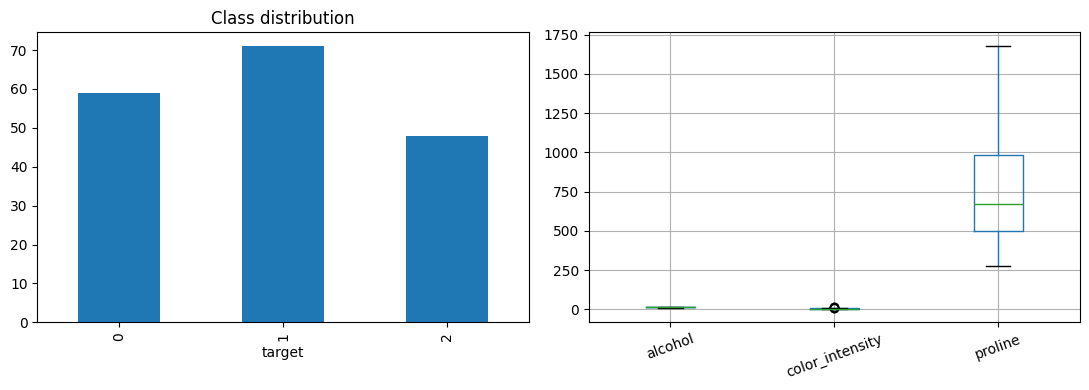

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y.value_counts().sort_index().plot.bar(ax=axes[0], title="Class distribution")
X[["alcohol", "color_intensity", "proline"]].boxplot(ax=axes[1], rot=20)
plt.tight_layout(); plt.show()

## 4. Stratified train–test split
Keep 25% of data untouched for final evaluation. All hyperparameter selection and cross-validation use training data only.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("Train:",X_train.shape,"Test:",X_test.shape)

Train: (133, 13) Test: (45, 13)


## 5. Inspect Gini and entropy splits

In [5]:
for criterion in ["gini", "entropy"]:
    model = DecisionTreeClassifier(max_depth=2, criterion=criterion, random_state=RANDOM_STATE).fit(X_train,y_train)
    root_feature = X.columns[model.tree_.feature[0]]
    root_threshold = model.tree_.threshold[0]
    print(f"{criterion}: first split = {root_feature} <= {root_threshold:.3f}; root impurity = {model.tree_.impurity[0]:.4f}")
    print(export_text(model, feature_names=list(X.columns), max_depth=2))

gini: first split = color_intensity <= 3.820; root impurity = 0.6585
|--- color_intensity <= 3.82
|   |--- ash <= 3.00
|   |   |--- class: 1
|   |--- ash >  3.00
|   |   |--- class: 0
|--- color_intensity >  3.82
|   |--- flavanoids <= 1.58
|   |   |--- class: 2
|   |--- flavanoids >  1.58
|   |   |--- class: 0

entropy: first split = flavanoids <= 1.575; root impurity = 1.5672
|--- flavanoids <= 1.58
|   |--- hue <= 0.90
|   |   |--- class: 2
|   |--- hue >  0.90
|   |   |--- class: 1
|--- flavanoids >  1.58
|   |--- alcohol <= 12.83
|   |   |--- class: 1
|   |--- alcohol >  12.83
|   |   |--- class: 0



## 6. Unrestricted versus controlled trees

In [6]:
models = {"Unrestricted": DecisionTreeClassifier(random_state=42),
          "Depth 3": DecisionTreeClassifier(max_depth=3, random_state=42),
          "Depth 3 + Leaf 5": DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=42),
          "Entropy Depth 3": DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows=[]
for name, model in models.items():
    model.fit(X_train,y_train)
    rows.append({"Model":name,"Train":model.score(X_train,y_train),"Test":model.score(X_test,y_test),
                 "F1":f1_score(y_test,model.predict(X_test),average="macro"),
                 "CV":cross_val_score(model,X_train,y_train,cv=cv).mean(),
                 "Depth":model.get_depth(),"Leaves":model.get_n_leaves()})
results=pd.DataFrame(rows)
display(results.round(4))

,Model,Train,Test,F1,CV,Depth,Leaves
0,Unrestricted,1.0000,0.9556,0.9565,0.9026,4,8
1,Depth 3,0.9925,0.9556,0.9565,0.9103,3,7
2,Depth 3 + Leaf 5,0.9699,0.9556,0.9586,0.9100,3,6
3,Entropy Depth 3,0.9850,0.9111,0.9147,0.9177,3,6


## 7. Visualize learned splits

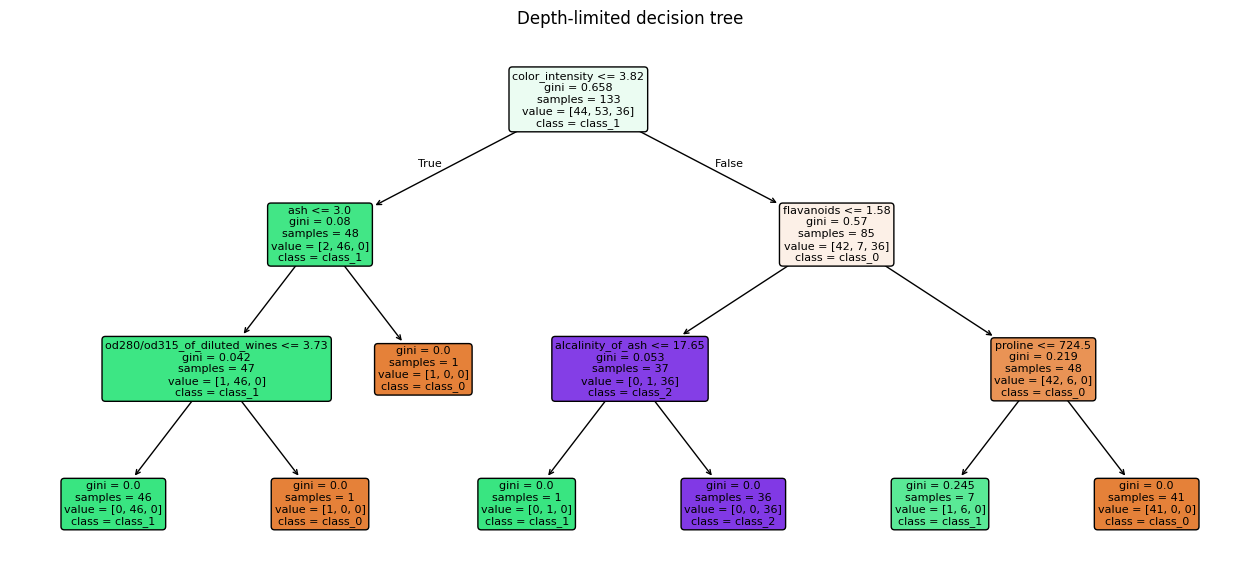

In [7]:
plt.figure(figsize=(16,7))
plot_tree(models["Depth 3"],feature_names=X.columns,class_names=wine.target_names,filled=True,rounded=True,fontsize=8)
plt.title("Depth-limited decision tree");plt.show()

## 8. Detect overfitting as depth increases

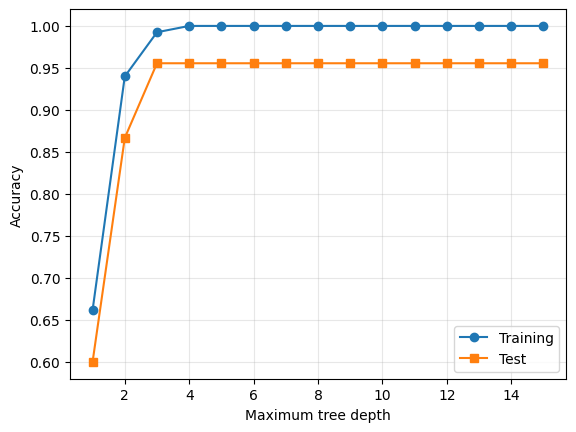

Interpretation: a widening train-test gap suggests overfitting; do not select depth using test results.


In [8]:
depths=range(1,16);train_scores=[];test_scores=[]
for depth in depths:
    m=DecisionTreeClassifier(max_depth=depth,random_state=42).fit(X_train,y_train)
    train_scores.append(m.score(X_train,y_train));test_scores.append(m.score(X_test,y_test))
plt.plot(depths,train_scores,"o-",label="Training");plt.plot(depths,test_scores,"s-",label="Test")
plt.xlabel("Maximum tree depth");plt.ylabel("Accuracy");plt.legend();plt.grid(alpha=.3);plt.show()
print("Interpretation: a widening train-test gap suggests overfitting; do not select depth using test results.")

## 9. Cost-complexity pruning (alpha chosen using training CV)

CV-selected alpha: 0.0


,alpha,train,test,cv,depth,leaves
0,0.0000,1.0000,0.9556,0.9026,4,8
1,0.0129,0.9925,0.9556,0.9026,3,7
2,0.0144,0.9774,0.9333,0.9026,3,5
3,0.0146,0.9699,0.9556,0.9026,3,4
4,0.0661,0.9323,0.8667,0.9026,2,3
5,0.2680,0.3985,0.4000,0.6764,0,1


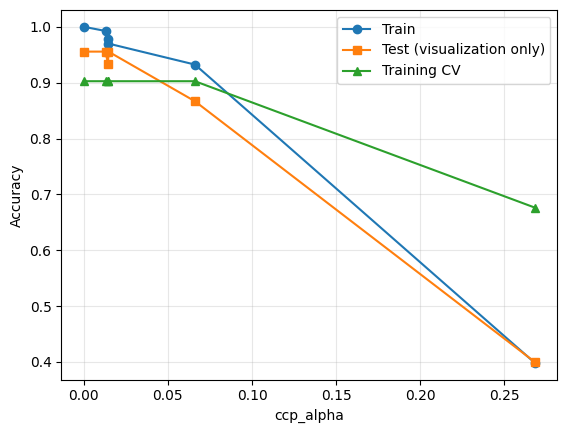

In [9]:
path=DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train,y_train)
prune_rows=[]
for alpha in np.unique(path.ccp_alphas):
    m=DecisionTreeClassifier(random_state=42,ccp_alpha=float(alpha)).fit(X_train,y_train)
    prune_rows.append({"alpha":alpha,"train":m.score(X_train,y_train),"test":m.score(X_test,y_test),
                       "cv":cross_val_score(m,X_train,y_train,cv=cv).mean(),"depth":m.get_depth(),"leaves":m.get_n_leaves()})
pruning=pd.DataFrame(prune_rows)
best_alpha=float(pruning.loc[pruning.cv.idxmax(),"alpha"])
pruned=DecisionTreeClassifier(random_state=42,ccp_alpha=best_alpha).fit(X_train,y_train)
print("CV-selected alpha:",best_alpha)
display(pruning.round(4))
plt.plot(pruning.alpha,pruning.train,"o-",label="Train")
plt.plot(pruning.alpha,pruning.test,"s-",label="Test (visualization only)")
plt.plot(pruning.alpha,pruning.cv,"^-",label="Training CV")
plt.xlabel("ccp_alpha");plt.ylabel("Accuracy");plt.legend();plt.grid(alpha=.3);plt.show()

## 10. Final comparison and confusion matrix

,Model,Train,Test,F1,CV,Depth,Leaves
0,Unrestricted,1.0000,0.9556,0.9565,0.9026,4,8
1,Depth 3,0.9925,0.9556,0.9565,0.9103,3,7
2,Depth 3 + Leaf 5,0.9699,0.9556,0.9586,0.9100,3,6
3,Entropy Depth 3,0.9850,0.9111,0.9147,0.9177,3,6
4,CV-selected pruning,1.0000,0.9556,0.9565,0.9026,4,8


              precision    recall  f1-score   support

     class_0       1.00      0.93      0.97        15
     class_1       0.90      1.00      0.95        18
     class_2       1.00      0.92      0.96        12

    accuracy                           0.96        45
   macro avg       0.97      0.95      0.96        45
weighted avg       0.96      0.96      0.96        45



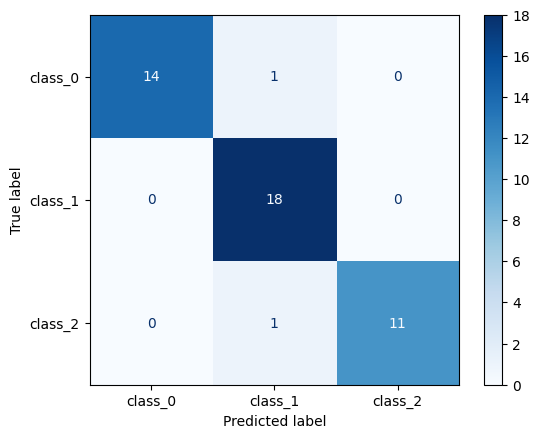

In [10]:
results.loc[len(results)]={"Model":"CV-selected pruning","Train":pruned.score(X_train,y_train),
 "Test":pruned.score(X_test,y_test),"F1":f1_score(y_test,pruned.predict(X_test),average="macro"),
 "CV":pruning.cv.max(),"Depth":pruned.get_depth(),"Leaves":pruned.get_n_leaves()}
display(results.round(4))
print(classification_report(y_test,models["Depth 3"].predict(X_test),target_names=wine.target_names))
ConfusionMatrixDisplay.from_estimator(models["Depth 3"],X_test,y_test,display_labels=wine.target_names,cmap="Blues")
plt.show()

## 11. Feature importance and limitations

flavanoids                      0.419003
color_intensity                 0.411369
proline                         0.102320
od280/od315_of_diluted_wines    0.022797
alcalinity_of_ash               0.022663
ash                             0.021847
magnesium                       0.000000
alcohol                         0.000000
dtype: float64


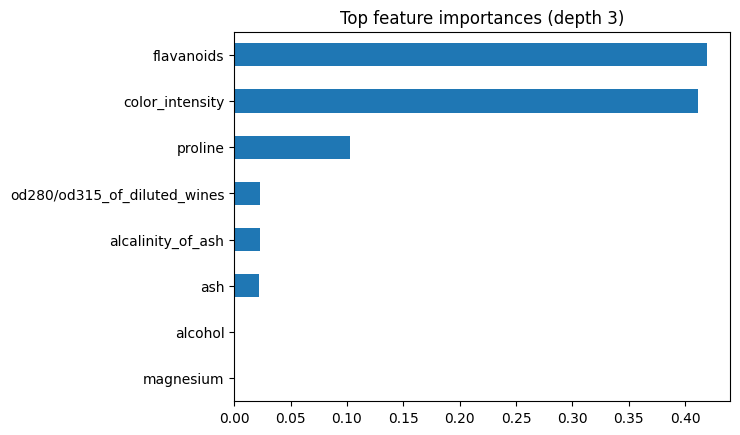

In [11]:
importance=pd.Series(models["Depth 3"].feature_importances_,index=X.columns).sort_values(ascending=False)
print(importance.head(8))
importance.head(8).sort_values().plot.barh(title="Top feature importances (depth 3)")
plt.show()

## 12. Interpretation and conclusion
- Splits choose feature thresholds that reduce Gini or entropy impurity.
- Unrestricted trees may attain near-perfect training accuracy without matching test performance.
- `max_depth`, `min_samples_leaf` and `ccp_alpha` constrain complexity.
- Select complexity using cross-validation on training data; use the holdout test set for final assessment.
- Small datasets lead to variable test estimates; feature importance is not causation.

**Dataset citation:** Forina et al., Wine Recognition dataset, UCI Machine Learning Repository; distributed through `sklearn.datasets.load_wine`.